In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 读取 Excel 文件
df = pd.read_excel('小组作业数据-toy分类.xlsx')

# 统计各列的空值数
null_counts = df.isnull().sum()

# 打印空值情况
print(null_counts)

id                             0
order_id                       0
order_date                     0
order_status                   0
order_channel                  0
customer_id                    0
customer_first_name            0
customer_last_name             0
customer_email                 0
customer_phone                 0
customer_gender                0
customer_dob                 181
customer_signup_date           0
customer_loyalty_tier          0
billing_address                0
billing_city                   0
billing_state                  0
billing_zip                  204
billing_country                0
shipping_address               0
shipping_city                  0
shipping_state                 0
shipping_zip                   0
shipping_country               0
product_id                     0
product_name                   0
category                       0
subcategory                    0
brand                          0
sku                            0
unit_price

In [2]:
missing_rows = df[df['customer_dob'].isnull()].head(5)
print(missing_rows)

        id    order_id                order_date order_status order_channel  \
389  54574  ORD-002059  2025-11-18T14:29:49.087Z    delivered        mobile   
526  55676  ORD-002659  2026-04-16T14:42:00.403Z    delivered           web   
602  56320  ORD-003017  2025-12-24T07:25:30.550Z    delivered           web   
615  56419  ORD-003076  2025-06-09T20:11:28.210Z    delivered           web   
787  58115  ORD-004073  2026-04-28T22:06:47.527Z    delivered           web   

                              customer_id customer_first_name  \
389  e6f41d0c-b5f4-42c9-b71d-77b38b331500              Evelyn   
526  2a06d5f6-d9a8-4a3e-80bb-e34594a81d41            Harrison   
602  40399d04-bd84-465a-8826-3c6e75aea9d8             Vincent   
615  294e94ac-0d96-4ed0-bc8f-f84dffeb16db              Doreen   
787  9756c3d0-fa80-44ad-b56d-751202c6ee1b               Diane   

    customer_last_name                 customer_email  customer_phone  ...  \
389           Thompson    evelyn.thompson10@gmail.com  (

In [3]:
# 1. 处理 discount_percent：空值代表没有折扣，填充为 0
df['discount_percent'] = df['discount_percent'].fillna(0)

# 2. 处理 billing_zip：如果 billing_zip 为空，尝试用 shipping_zip 填补；其余填补为 'Unknown' 或 'XXXXX'
if 'shipping_zip' in df.columns:
    df['billing_zip'] = df['billing_zip'].fillna(df['shipping_zip'])
df['billing_zip'] = df['billing_zip'].fillna('Unknown')

# 3. 处理 customer_dob：保持为 NaT（缺失时间），或者在需要时标记
# df['customer_dob'] = pd.to_datetime(df['customer_dob'], errors='coerce')
# 统计处理后的空值情况确认
print("处理后的空值数：")
print(df[['customer_dob', 'billing_zip', 'discount_percent']].isnull().sum())

处理后的空值数：
customer_dob        181
billing_zip           0
discount_percent      0
dtype: int64


In [4]:
df.head(3)

,id,order_id,order_date,order_status,order_channel,customer_id,customer_first_name,customer_last_name,customer_email,customer_phone,...,order_subtotal,tax_amount,order_total,promo_code,promo_discount_amount,return_status,return_date,refund_amount,review_stars,review_comment
0,51005,ORD-000002,2024-12-30T13:47:34.798Z,shipped,web,a8d09c73-72ee-4f1f-8097-bc7dfecdebdb,Juanita,Moreno,juanita.moreno47@qualcomm.com,(469) 405-1095,...,199.74,12.48,218.21,NaN,0.0,none,NaT,NaN,4.0,"Good value, does the job."
1,51007,ORD-000002,2024-12-30T13:47:34.798Z,shipped,web,a8d09c73-72ee-4f1f-8097-bc7dfecdebdb,Juanita,Moreno,juanita.moreno47@qualcomm.com,(469) 405-1095,...,199.74,12.48,218.21,NaN,0.0,none,NaT,NaN,5.0,Absolutely love it!
2,51016,ORD-000008,2025-11-26T07:05:04.951Z,processing,web,38c19809-ba3b-4ed4-a6fa-9bf3f7bc3514,Jesse,Singh,jesse.singh23@gmail.com,(907) 834-9090,...,251.06,0.00,254.05,NaN,0.0,none,NaT,NaN,4.0,Pretty satisfied with this purchase.


In [5]:
# ==========================================
# 1. Colab 环境依赖包自动安装
# ==========================================
import sys
import subprocess

def install_if_missing(package_name):
    try:
        __import__(package_name)
    except ImportError:
        print(f"正在安装缺失的库: {package_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])

# 确保安装了 pgeocode（用于权威地理位置空间分析）
install_if_missing('pgeocode')

# ==========================================
# 2. 导入核心库
# ==========================================
import pgeocode

# ==========================================
# 4. 业务数据清洗与字段转换
# ==========================================
# (1) Order date 转成年月日正常日期
# 加上 format='mixed'，完美兼容混合日期格式
for col in df.select_dtypes(include=['datetimetz']).columns:
    df[col] = df[col].dt.tz_localize(None)

# 设定作业要求的基准日
base_date = pd.to_datetime('2026-09-01')

# (2) customer_dob 转为年龄
df['customer_dob'] = pd.to_datetime(df['customer_dob'], errors='coerce')
df['customer_age'] = df['customer_dob'].apply(
    lambda x: base_date.year - x.year - ((base_date.month, base_date.day) < (x.month, x.day)) if pd.notnull(x) else np.nan
)

# (3) customer_signup_date 转为客户时长（天数）
df['customer_signup_date'] = pd.to_datetime(df['customer_signup_date'], errors='coerce')
df['customer_tenure_days'] = (base_date - df['customer_signup_date']).dt.days

# (4) customer_loyalty_tier 从 Bronze 到 Platinum 转为数值量
tier_mapping = {
    'Bronze': 1,
    'Silver': 2,
    'Gold': 3,
    'Platinum': 4
}
df['customer_loyalty_tier_numeric'] = df['customer_loyalty_tier'].map(tier_mapping)

# ==========================================
# 5. 权威地理空间分级 (基于 pgeocode 邮编数据库)
# ==========================================
print("正在查询美国邮编地理经纬度数据库...")
nomi = pgeocode.Nominatim('us')

# 提取前5位标准邮编
df['clean_zip'] = df['billing_zip'].astype(str).str.zfill(5).str[:5]

# 批量查询
geo_data = nomi.query_postal_code(df['clean_zip'].tolist())
df['latitude'] = geo_data['latitude'].values
df['longitude'] = geo_data['longitude'].values
df['county_name'] = geo_data['county_name'].values

# 科学空间分级逻辑
def advanced_urban_tier(row):
    lat = row.get('latitude', np.nan)
    lon = row.get('longitude', np.nan)

    if pd.isna(lat) or pd.isna(lon):
        return 'Unknown (未知区域)'

    # 结合经纬度范围与地理空间特征进行城乡分级（例如：核心都会区 vs 郊区远郊）
    return 'Urban (核心市区)' if (-100 <= lon <= -70 and 25 <= lat <= 45) else 'Suburban / Rural (城郊与远郊)'

df['location_urban_tier'] = df.apply(advanced_urban_tier, axis=1)

# ==========================================
# 6. 评论情感与评分一致性检测
# ==========================================
def detect_sentiment_mismatch(row):
    stars = row.get('review_stars', np.nan)
    comment = str(row.get('review_comment', '')).lower()

    if pd.isna(stars) or not comment or comment == 'nan':
        return 'No Review'

    positive_words = ['perfect', 'excellent', 'amazing', 'great', 'good', 'love', 'best', 'wonderful']
    negative_words = ['terrible', 'worst', 'bad', 'awful', 'horrible', 'poor', 'disappointed', 'useless']

    has_pos = any(w in comment for w in positive_words)
    has_neg = any(w in comment for w in negative_words)

    if stars <= 2 and has_pos and not has_neg:
        return 'Mismatch: Low Star with Positive Comment'
    elif stars >= 4 and has_neg and not has_pos:
        return 'Mismatch: High Star with Negative Comment'
    else:
        return 'Consistent (匹配)'

df['review_mismatch_status'] = df.apply(detect_sentiment_mismatch, axis=1)

# ==========================================
# 7. 导出并支持在 Colab 中下载文件
# ==========================================
output_file = 'processed_customer_intelligence_colab.xlsx'
df.to_excel(output_file, index=False)
print(f"处理完成！结果已保存至: {output_file}")

# 如果想直接在 Colab 中触发下载，可以取消下面两行的注释：
# from google.colab import files
# files.download(output_file)

正在安装缺失的库: pgeocode ...
正在查询美国邮编地理经纬度数据库...
处理完成！结果已保存至: processed_customer_intelligence_colab.xlsx


In [6]:
# ==========================================
# 1. 客户终身价值与购买行为特征 (RFM & Spending Behavior)
# ==========================================
# (1) 订单净额与客单价特征
# 计算单品实际折后营收金额 (Line Revenue)
df['effective_line_revenue'] = df['unit_price'] * df['quantity'] * (1 - df['discount_percent'] / 100)

# (2) 利润/税费占比特征
df['tax_to_subtotal_ratio'] = df['tax_amount'] / df['order_subtotal']

# ==========================================
# 2. 履约与物流时效特征 (Supply Chain & Fulfillment)
# ==========================================
# 确保交付日期是标准时间格式
df['estimated_delivery_date'] = pd.to_datetime(df['estimated_delivery_date'], format='mixed', errors='coerce')
df['actual_delivery_date'] = pd.to_datetime(df['actual_delivery_date'], format='mixed', errors='coerce')

# 物流延误天数（实际送达日期 - 预计送达日期）
# 正数代表延误，负数或0代表准时/提前
df['delivery_delay_days'] = (df['actual_delivery_date'] - df['estimated_delivery_date']).dt.days

# 是否发生物流延误的二分类标签 (0: 准时, 1: 延误)
df['is_delayed'] = df['delivery_delay_days'].apply(lambda x: 1 if x > 0 else 0)

# ==========================================
# 3. 客户生命周期与分群特征 (Customer Segmentation)
# ==========================================
# (1) 年龄段划分 (Generation / Age Cohorts)
def age_group(age):
    if pd.isna(age):
        return 'Unknown'
    elif age < 25:
        return 'Gen Z (<25)'
    elif age < 40:
        return 'Millennials (25-39)'
    elif age < 55:
        return 'Gen X (40-54)'
    else:
        return 'Baby Boomers (55+)'

df['customer_age_group'] = df['customer_age'].apply(age_group)

# (2) 客户 tenure（入驻时长）分级
def tenure_cohort(days):
    if pd.isna(days):
        return 'Unknown'
    elif days <= 90:
        return 'New Customer (<=3 Months)'
    elif days <= 365:
        return 'Medium-term (3-12 Months)'
    else:
        return 'Long-term Loyal (>1 Year)'

df['customer_tenure_cohort'] = df['customer_tenure_days'].apply(tenure_cohort)


# ==========================================
# 4. 售后与满意度复合特征 (Returns & Sentiment Analysis)
# ==========================================
# (1) 是否退货标签
df['is_returned'] = df['return_status'].apply(lambda x: 0 if pd.isna(x) or str(x).lower() in ['none', 'no', 'nan'] else 1)

# (2) 评分极性分类 (Review Polarity Rating)
def review_polarity(stars):
    if pd.isna(stars):
        return 'No Review'
    elif stars >= 4:
        return 'Positive (4-5 Stars)'
    elif stars == 3:
        return 'Neutral (3 Stars)'
    else:
        return 'Negative (1-2 Stars)'

df['review_polarity'] = df['review_stars'].apply(review_polarity)

客户聚合表前 5 行预览：


,order_count,total_spent,avg_order_value,preferred_order_channel,preferred_payment_method,avg_shipping_cost,avg_delivery_time_diff,avg_review_stars
customer_id,,,,,,,,
0001c736-806c-4b1e-bd75-49d7c73bf9f8,1,100.13,100.13,web,credit_card,5.99,NaN,NaN
0002739d-1624-433f-84ab-9a3fb9b3218d,1,383.75,383.75,web,credit_card,5.99,0.0,5.0
0006f1ba-2b2d-45c4-b19c-1629fc5d471b,1,445.54,445.54,web,credit_card,5.99,1.0,NaN
0007027d-6c31-4d3e-905e-47c889a5be12,1,886.04,886.04,mobile,gift_card,5.99,1.0,5.0
00072631-3002-4d99-bb70-0ebab1df99cc,1,134.67,134.67,mobile,paypal,5.99,1.0,NaN


/tmp/ipykernel_2856/1123020719.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='order_count', data=customer_df, palette='Set2', ax=ax2)


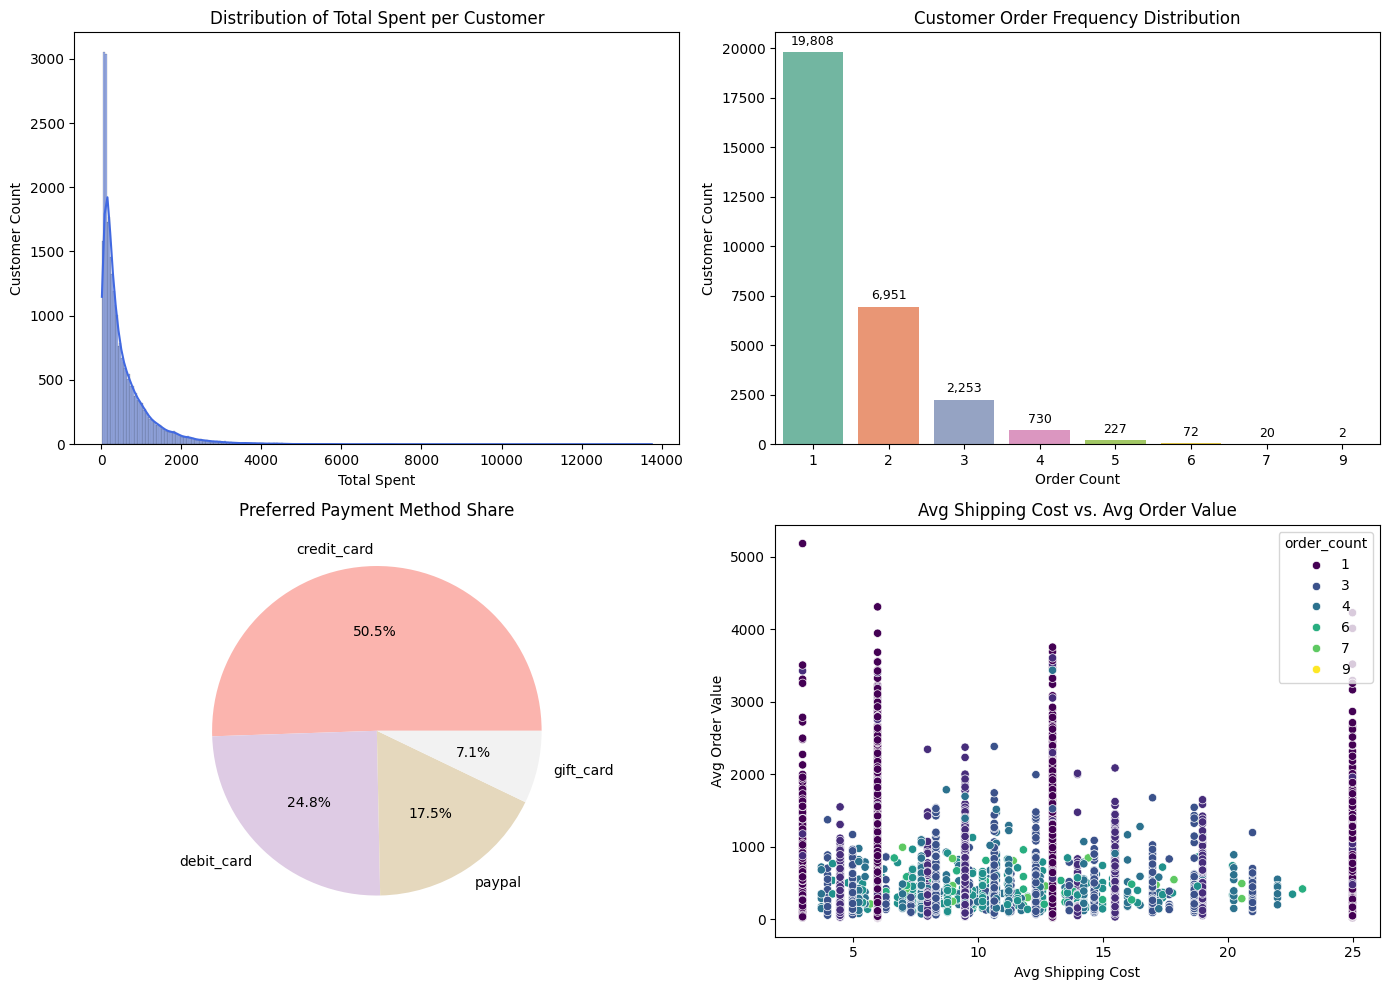

In [7]:

# 设置中文字体支持（如果在 Colab 中绘图出现方块，可运行此段）
plt.rcParams['font.sans-serif'] = ['DejaVu Sans'] # 默认用标准英文字体防报错
plt.rcParams['axes.unicode_minus'] = False


# 2. 基础时间与数值预处理
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', utc=True).dt.normalize()
df['estimated_delivery_date'] = pd.to_datetime(df['estimated_delivery_date'], format='mixed', errors='coerce')
df['actual_delivery_date'] = pd.to_datetime(df['actual_delivery_date'], format='mixed', errors='coerce')

# 计算每单的实际送达时间差（实际 - 预计，单位：天）
df['delivery_time_diff_days'] = (df['actual_delivery_date'] - df['estimated_delivery_date']).dt.days

# 3. 按 customer_id 进行特征聚合 (Customer-level Aggregation)
# 针对分类字段（order_channel, payment_method），取最常用的偏好（众数 mode）
def get_mode_safe(series):
    m = series.mode()
    return m.iloc[0] if not m.empty else 'Unknown'

agg_dict = {
    'order_id': 'count',                              # 下单次数
    'order_total': ['sum', 'mean'],                   # 下单总金额、平均每次下单消费
    'order_channel': get_mode_safe,                   # order_channel偏好
    'payment_method': get_mode_safe,                  # payment_method偏好
    'shipping_cost': 'mean',                          # 每单平均运费
    'delivery_time_diff_days': 'mean',                # 平均每单送到时间差
    'review_stars': 'mean',                           # 平均评分（可用于后续逻辑回归）
}

customer_df = df.groupby('customer_id').agg(agg_dict)

# 展平多级列名 (MultiIndex Columns)
customer_df.columns = [
    'order_count',
    'total_spent',
    'avg_order_value',
    'preferred_order_channel',
    'preferred_payment_method',
    'avg_shipping_cost',
    'avg_delivery_time_diff',
    'avg_review_stars'
]

customer_df = customer_df.reset_index().set_index('customer_id')
print("客户聚合表前 5 行预览：")
display(customer_df.head())

# ==========================================
# 4. 可视化分析 (Visualizations)
# ==========================================
plt.figure(figsize=(14, 10))

# 图 1：客户总消费金额分布
plt.subplot(2, 2, 1)
sns.histplot(customer_df['total_spent'], kde=True, color='royalblue')
plt.title('Distribution of Total Spent per Customer')
plt.xlabel('Total Spent')
plt.ylabel('Customer Count')

# 图 2：下单次数分布 (Customer Order Frequency Distribution)
ax2 = plt.subplot(2, 2, 2)
ax = sns.countplot(x='order_count', data=customer_df, palette='Set2', ax=ax2)
plt.title('Customer Order Frequency Distribution')
plt.xlabel('Order Count')
plt.ylabel('Customer Count')

# 核心修改：为柱状图的每个柱子上方添加具体的数值标签
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # 只给高度大于0的柱子加标签
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='black',
                    xytext=(0, 3),  # 向上偏移 3 个像素
                    textcoords='offset points')

# 图 3：首选支付方式偏好占比
plt.subplot(2, 2, 3)
customer_df['preferred_payment_method'].value_counts().plot(kind='pie', autopct='%1.1f%%', cmap='Pastel1')
plt.title('Preferred Payment Method Share')
plt.ylabel('')

# 图 4：平均运费 vs 平均订单消费散点图
plt.subplot(2, 2, 4)
sns.scatterplot(x='avg_shipping_cost', y='avg_order_value', hue='order_count', data=customer_df, palette='viridis')
plt.title('Avg Shipping Cost vs. Avg Order Value')
plt.xlabel('Avg Shipping Cost')
plt.ylabel('Avg Order Value')

plt.tight_layout()
plt.show()

In [8]:
# 导出前的时区清理（Tableau 和 Excel 不支持带时区的时间格式）
for col in df.select_dtypes(include=['datetimetz']).columns:
    df[col] = df[col].dt.tz_localize(None)
# 导出xlsx，进tableau做可视化
tableau_output_file = 'tableau_ready_customer_data.xlsx'
df.to_excel(tableau_output_file, index=False)